In [17]:
import pandas as pd
df=pd.read_csv("d/de.csv")
df.head()
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [18]:
df=df.drop("customerID",axis=1)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
y=df['Churn']
y=y.map({'yes':1,
        'No':0})
y.head()

0    0.0
1    0.0
2    NaN
3    0.0
4    NaN
Name: Churn, dtype: float64

In [20]:
y.isnull().sum()
y=y.dropna()

In [21]:
y.isnull().sum()

np.int64(0)

In [22]:
print(y.unique())
print(df["Churn"].apply(repr).unique())

[0.]
<StringArray>
[''No'', ''Yes'']
Length: 2, dtype: str


In [23]:
X = df.drop("Churn", axis=1)
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in y:", y.isnull().sum())
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)
Missing values in y: 0
Churn
0    5174
1    1869
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df,y,test_size=0.2,random_state=42,stratify=y)
print(X_train)
print(X_test)
print(y_train)
print(y_test)



      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
3738    Male              0      No         No      35           No   
3151    Male              0     Yes        Yes      15          Yes   
4860    Male              0     Yes        Yes      13           No   
3867  Female              0     Yes         No      26          Yes   
3810    Male              0     Yes        Yes       1          Yes   
...      ...            ...     ...        ...     ...          ...   
6303  Female              0     Yes         No      71          Yes   
6227    Male              0      No         No       2          Yes   
4673  Female              1      No         No      25          Yes   
2710  Female              0     Yes         No      24          Yes   
5639    Male              0      No         No       6          Yes   

         MultipleLines InternetService       OnlineSecurity  \
3738  No phone service             DSL                   No   
3151                N

In [25]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


/var/folders/6f/6kps40tj0lscbkdz6qrp94vr0000gn/T/ipykernel_3171/1998881318.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [26]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'Churn']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [29]:
y_pred = logistic_model.predict(X_test)
print(y_pred[:20])

[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [30]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.794180269694819


In [31]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[917 118]
 [172 202]]


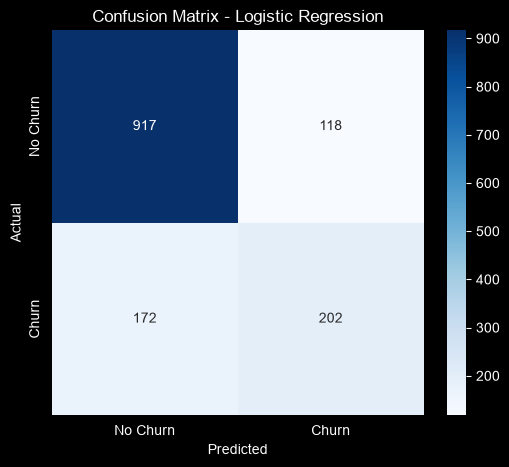

In [33]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [34]:
from sklearn.metrics import roc_auc_score

y_probability = logistic_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8402981218837996


In [35]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

In [36]:
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [37]:
rf_pred = random_forest_model.predict(X_test)
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1035
           1       0.55      0.64      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409



In [38]:
rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_probability)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.8219638843679764


In [39]:
from xgboost import XGBClassifier
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric="logloss"
        ))
    ]
)

In [40]:
xgb_model.fit(X_train, y_train)
print("XGBoost trained successfully!")

XGBoost trained successfully!


In [41]:
xgb_pred = xgb_model.predict(X_test)

In [42]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.64      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



In [43]:
xgb_probability = xgb_model.predict_proba(X_test)[:, 1]

xgb_auc = roc_auc_score(
    y_test,
    xgb_probability
)
print("XGBoost ROC-AUC:", xgb_auc)

XGBoost ROC-AUC: 0.8400759513291484


In [44]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, random_forest_model.predict_proba(X_test)[:, 1]),
        xgb_auc
    ]
})

model_results

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.794180,0.840298
1,Random Forest,0.764372,0.821964
2,XGBoost,0.794180,0.840076


In [46]:
from sklearn.metrics import recall_score, f1_score

model_results["Churn Recall"] = [
    recall_score(y_test, y_pred),
    recall_score(y_test, rf_pred),
    recall_score(y_test, xgb_pred)
]

model_results["Churn F1"] = [
    f1_score(y_test, y_pred),
    f1_score(y_test, rf_pred),
    f1_score(y_test, xgb_pred)
]

model_results

,Model,Accuracy,ROC-AUC,Churn Recall,Churn F1
0,Logistic Regression,0.794180,0.840298,0.540107,0.582133
1,Random Forest,0.764372,0.821964,0.636364,0.589109
2,XGBoost,0.794180,0.840076,0.518717,0.572271


In [48]:
from sklearn.model_selection import GridSearchCV

rf_params = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    random_forest_model,
    param_grid=rf_params,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best Cross-Validation ROC-AUC:")
print(rf_grid.best_score_)

Best Random Forest Parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
Best Cross-Validation ROC-AUC:
0.837038159264149


In [49]:
best_rf = rf_grid.best_estimator_

best_rf_pred = best_rf.predict(X_test)
best_rf_probability = best_rf.predict_proba(X_test)[:, 1]

print("Tuned Random Forest")
print("-------------------")
print("Accuracy:", accuracy_score(y_test, best_rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, best_rf_probability))
print("Churn Recall:", recall_score(y_test, best_rf_pred))
print("Churn F1:", f1_score(y_test, best_rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, best_rf_pred))

Tuned Random Forest
-------------------
Accuracy: 0.7374024130589071
ROC-AUC: 0.8254346534397685
Churn Recall: 0.7807486631016043
Churn F1: 0.6121593291404612

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [50]:
print("BASELINE RANDOM FOREST")
print("ROC-AUC:", roc_auc_score(
    y_test,
    random_forest_model.predict_proba(X_test)[:, 1]
))

print("Churn Recall:", recall_score(y_test, rf_pred))
print("Churn F1:", f1_score(y_test, rf_pred))

print("\nTUNED RANDOM FOREST")
print("ROC-AUC:", roc_auc_score(y_test, best_rf_probability))
print("Churn Recall:", recall_score(y_test, best_rf_pred))
print("Churn F1:", f1_score(y_test, best_rf_pred))

BASELINE RANDOM FOREST
ROC-AUC: 0.8219638843679764
Churn Recall: 0.6363636363636364
Churn F1: 0.5891089108910891

TUNED RANDOM FOREST
ROC-AUC: 0.8254346534397685
Churn Recall: 0.7807486631016043
Churn F1: 0.6121593291404612


In [51]:
xgb_params = {
    "classifier__n_estimators": [200, 300],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [3, 4, 5],
    "classifier__subsample": [0.8],
    "classifier__colsample_bytree": [0.8]
}

xgb_grid = GridSearchCV(
    xgb_model,
    param_grid=xgb_params,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

print("Best Cross-Validation ROC-AUC:")
print(xgb_grid.best_score_)

Best XGBoost Parameters:
{'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}
Best Cross-Validation ROC-AUC:
0.8509491930412615


In [52]:
best_xgb = xgb_grid.best_estimator_

best_xgb_pred = best_xgb.predict(X_test)
best_xgb_probability = best_xgb.predict_proba(X_test)[:, 1]

print("Tuned XGBoost")
print("-------------")
print("Accuracy:", accuracy_score(y_test, best_xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, best_xgb_probability))
print("Churn Recall:", recall_score(y_test, best_xgb_pred))
print("Churn F1:", f1_score(y_test, best_xgb_pred))

print("\nClassification Report:")
print(classification_report(y_test, best_xgb_pred))

Tuned XGBoost
-------------
Accuracy: 0.8034066713981547
ROC-AUC: 0.8470342814332584
Churn Recall: 0.5187165775401069
Churn F1: 0.5834586466165413

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [54]:
print("Best Parameters:")
print(xgb_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(xgb_grid.best_score_)
print("Tuned XGBoost Test ROC-AUC:",
      roc_auc_score(y_test, best_xgb_probability))

Best Parameters:
{'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}

Best CV ROC-AUC:
0.8509491930412615
Tuned XGBoost Test ROC-AUC: 0.8470342814332584


In [55]:
final_model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Tuned Random Forest",
        "XGBoost",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, best_rf_pred),
        accuracy_score(y_test, xgb_pred),
        accuracy_score(y_test, best_xgb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(
            y_test,
            logistic_model.predict_proba(X_test)[:, 1]
        ),
        roc_auc_score(
            y_test,
            random_forest_model.predict_proba(X_test)[:, 1]
        ),
        roc_auc_score(
            y_test,
            best_rf_probability
        ),
        xgb_auc,
        roc_auc_score(
            y_test,
            best_xgb_probability
        )
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, best_rf_pred),
        recall_score(y_test, xgb_pred),
        recall_score(y_test, best_xgb_pred)
    ],
    "Churn F1": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, best_rf_pred),
        f1_score(y_test, xgb_pred),
        f1_score(y_test, best_xgb_pred)
    ]
})

final_model_results

,Model,Accuracy,ROC-AUC,Churn Recall,Churn F1
0,Logistic Regression,0.794180,0.840298,0.540107,0.582133
1,Random Forest,0.764372,0.821964,0.636364,0.589109
2,Tuned Random Forest,0.737402,0.825435,0.780749,0.612159
3,XGBoost,0.794180,0.840076,0.518717,0.572271
4,Tuned XGBoost,0.803407,0.847034,0.518717,0.583459


In [56]:
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()

feature_importance = best_rf.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
1,num__tenure,0.081421
35,cat__Contract_Month-to-month,0.067325
17,cat__OnlineSecurity_No,0.051623
37,cat__Contract_Two year,0.044537
2,num__MonthlyCharges,0.043144
26,cat__TechSupport_No,0.041742
15,cat__InternetService_Fiber optic,0.035970
42,cat__PaymentMethod_Electronic check,0.028355
36,cat__Contract_One year,0.025622
20,cat__OnlineBackup_No,0.025503


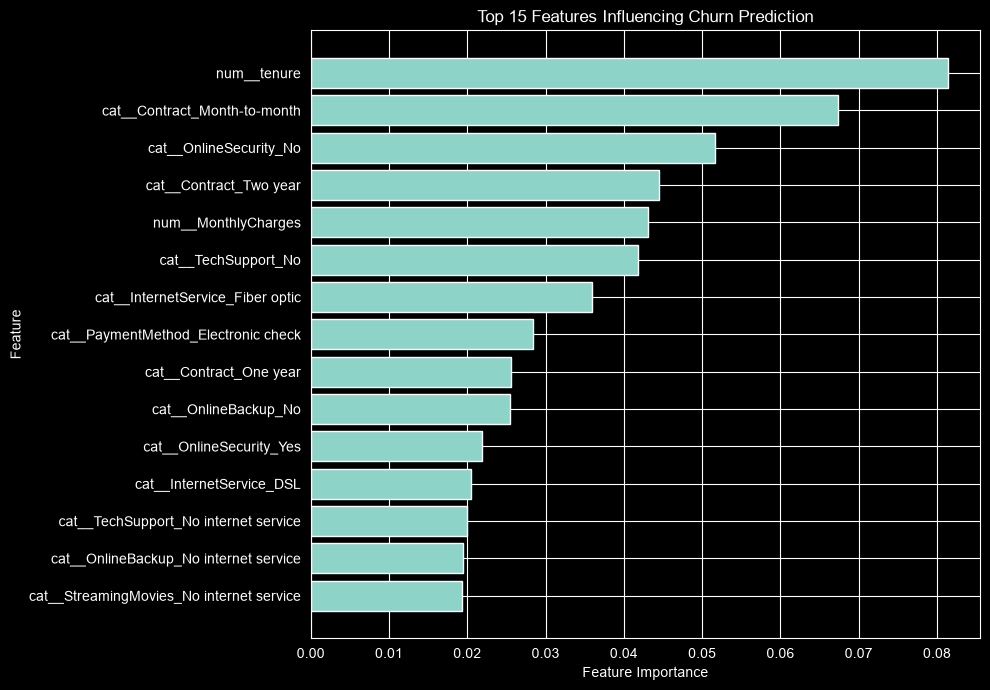

In [57]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Influencing Churn Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [59]:
final_model = best_rf
final_probability = final_model.predict_proba(X_test)[:, 1]
final_prediction = final_model.predict(X_test)
print("First 10 churn probabilities:")
print(final_probability[:10])

First 10 churn probabilities:
[0.18304558 0.70682697 0.22204537 0.58433747 0.19893853 0.70553087
 0.60959884 0.1764442  0.06363487 0.69639274]


In [60]:
def risk_category(probability):
    if probability < 0.30:
        return "Low"
    elif probability < 0.60:
        return "Medium"
    else:
        return "High"

In [61]:
print(risk_category(0.18))
print(risk_category(0.45))
print(risk_category(0.82))

Low
Medium
High


In [62]:
prediction_results = X_test.copy()
prediction_results["Actual_Churn"] = y_test.values
prediction_results["Churn_Probability"] = final_probability
prediction_results["Risk_Level"] = [
    risk_category(p) for p in final_probability
]
prediction_results.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Actual_Churn,Churn_Probability,Risk_Level
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2,No,0,0.183046,Low
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,No,0,0.706827,High
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,One year,Yes,Credit card (automatic),78.35,3211.2,No,0,0.222045,Low
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,Month-to-month,No,Electronic check,78.20,1468.75,No,0,0.584337,Medium
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,No,0,0.198939,Low


In [63]:
prediction_results["Risk_Level"].value_counts()

Risk_Level
Low       522
Medium    459
High      428
Name: count, dtype: int64

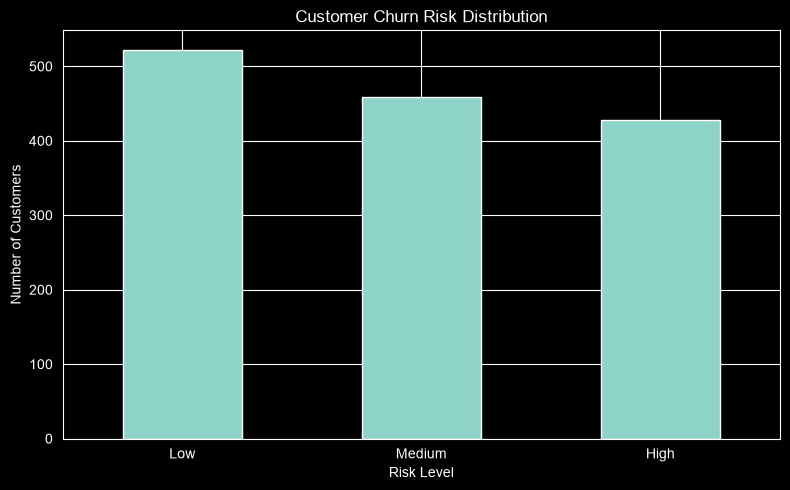

In [64]:
prediction_results["Risk_Level"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
import joblib
joblib.dump(
    final_model,
    "final_churn_model.pkl"
)

['final_churn_model.pkl']

In [67]:
loaded_model = joblib.load("final_churn_model.pkl")

test_probability = loaded_model.predict_proba(X_test.iloc[:5])[:, 1]

print("Test probabilities:")
print(test_probability)

Test probabilities:
[0.18304558 0.70682697 0.22204537 0.58433747 0.19893853]


In [69]:
print("Expected model input columns:")
print(final_model.feature_names_in_)

print("\nNumber of features:")
print(len(final_model.feature_names_in_))

Expected model input columns:
['gender' 'SeniorCitizen' 'Partner' 'Dependents' 'tenure' 'PhoneService'
 'MultipleLines' 'InternetService' 'OnlineSecurity' 'OnlineBackup'
 'DeviceProtection' 'TechSupport' 'StreamingTV' 'StreamingMovies'
 'Contract' 'PaperlessBilling' 'PaymentMethod' 'MonthlyCharges'
 'TotalCharges' 'Churn']

Number of features:
20


In [70]:
print(X.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [71]:
3
import joblib

model = joblib.load("final_churn_model.pkl")
preprocessor = model.named_steps["preprocessor"]

print("Model steps:", model.named_steps.keys())
print("\nExpected input columns:")
print(preprocessor.feature_names_in_.tolist())

print("\nPreprocessor configuration:")
print(preprocessor)

print("\nTransformer details:")
for name, transformer, columns in preprocessor.transformers_:
    print(f"\n{name}:")
    print("Transformer:", transformer)
    print("Columns:", columns)


Model steps: dict_keys(['preprocessor', 'classifier'])

Expected input columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Preprocessor configuration:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                     

In [72]:

# Check whether Churn was accidentally included in X
print("X columns:")
print(X.columns.tolist())

print("\nDoes X contain Churn?")
print("Churn" in X.columns)

print("\nTarget y:")
print(y.name)
print(y.value_counts(dropna=False))

print("\nModel's preprocessor input columns:")
print(model.named_steps["preprocessor"].feature_names_in_.tolist())


X columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Does X contain Churn?
False

Target y:
Churn
Churn
0    5174
1    1869
Name: count, dtype: int64

Model's preprocessor input columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [73]:

# Check the selected tuned XGBoost model and training inputs
print("X_train contains Churn:", "Churn" in X_train.columns)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nPreprocessor numerical columns:")
print(numerical_features)

print("\nPreprocessor categorical columns:")
print(categorical_features)


X_train contains Churn: True
X_train shape: (5634, 20)
y_train shape: (5634,)

Preprocessor numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Preprocessor categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


In [74]:

# Remove the target column from the input features
X_train = X_train.drop(columns=["Churn"], errors="ignore")
X_test = X_test.drop(columns=["Churn"], errors="ignore")

# Verify
print("Churn in X_train:", "Churn" in X_train.columns)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Churn in X_train: False
X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [75]:

# Refit the tuned XGBoost model using the corrected training data
xgb_grid.best_estimator_.fit(X_train, y_train)

# Save the corrected final model
import joblib

final_model = xgb_grid.best_estimator_
joblib.dump(final_model, "final_churn_model.pkl")

print("Final XGBoost model trained and saved successfully!")


Final XGBoost model trained and saved successfully!


In [76]:

loaded_model = joblib.load("final_churn_model.pkl")

print("Expected features:")
print(list(loaded_model.feature_names_in_)
      if hasattr(loaded_model, "feature_names_in_")
      else list(loaded_model.named_steps["preprocessor"].feature_names_in_))

print("\nTest probabilities:")
print(loaded_model.predict_proba(X_test.iloc[:5])[:, 1])


Expected features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Test probabilities:
[0.02603088 0.7527718  0.06378764 0.33468962 0.0190919 ]


In [77]:

import joblib
import pandas as pd
import numpy as np

model = joblib.load("final_churn_model.pkl")

test_customer = X_test.iloc[[0]].copy()

print("Input shape:", test_customer.shape)
print("Input types:")
print(test_customer.dtypes)

try:
    result = model.predict_proba(test_customer)
    print("\nPrediction successful!")
    print("Probabilities:", result)
except Exception as e:
    print("\nPrediction failed!")
    print(type(e).__name__, str(e))


Input shape: (1, 19)
Input types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
dtype: object

Prediction successful!
Probabilities: [[0.9739691  0.02603088]]


In [78]:

try:
    print(model.predict_proba(X_test.iloc[[0]]))
    print("MODEL TEST PASSED")
except Exception as e:
    print("MODEL TEST FAILED")
    print(repr(e))


[[0.9739691  0.02603088]]
MODEL TEST PASSED
